In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df_house = pd.read_csv("cleandataset.csv")
df_house.head()

,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view_quality,condition,grade,...,lat,long,sqft_living15,sqft_lot15,date,price,basement_was_missing,view_was_missing,is_renovated,renovated_was_missing
0,7129300520,3.0,1.00,1180.0,5650.0,1.0,0,0.0,3,7,...,47.5112,-122.257,1340.0,5650.0,2014-10-13,221900.0,0,0,0,0
1,6414100192,3.0,2.25,2570.0,7242.0,2.0,0,0.0,3,7,...,47.7210,-122.319,1690.0,7639.0,2014-12-09,538000.0,0,0,1,0
2,5631500400,2.0,1.00,770.0,10000.0,1.0,0,0.0,3,6,...,47.7379,-122.233,2720.0,8062.0,2015-02-25,180000.0,0,0,0,0
3,2487200875,4.0,3.00,1960.0,5000.0,1.0,0,0.0,5,7,...,47.5208,-122.393,1360.0,5000.0,2014-12-09,604000.0,0,0,0,0
4,1954400510,3.0,2.00,1680.0,8080.0,1.0,0,0.0,3,8,...,47.6168,-122.045,1800.0,7503.0,2015-02-18,510000.0,0,0,0,0


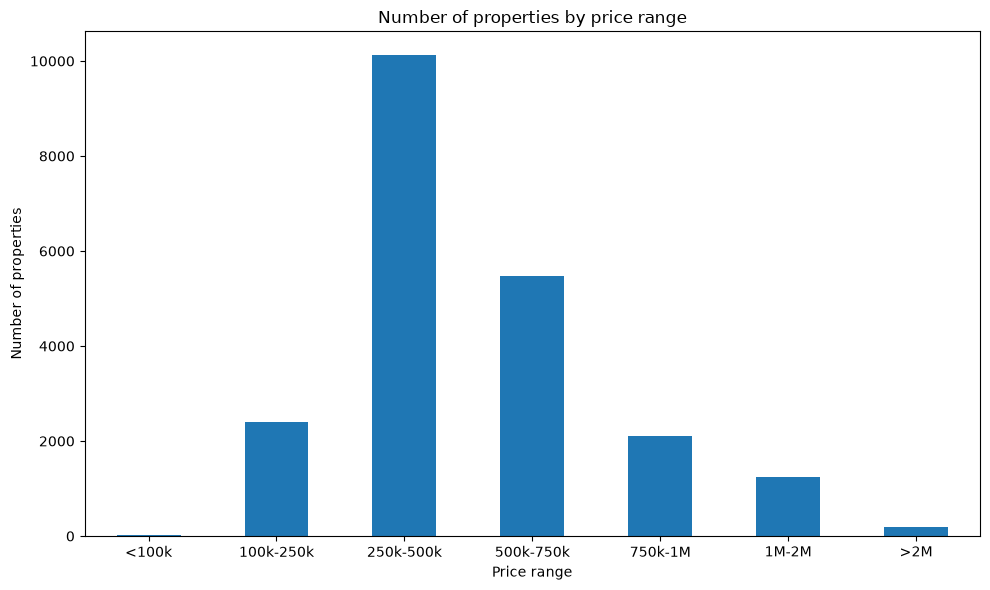

In [2]:
# Define price ranges
bins = [0,100_000, 250_000, 500_000, 750_000, 1_000_000, 2_000_000, df_house["price"].max()]
labels = ["<100k","100k-250k", "250k-500k", "500k-750k", "750k-1M", "1M-2M", ">2M"]

df_house["price_range"] = pd.cut(df_house["price"], bins=bins, labels=labels)

# Plot
df_house["price_range"].value_counts().sort_index().plot(kind="bar", figsize=(10, 6))
plt.title("Number of properties by price range")
plt.xlabel("Price range")
plt.ylabel("Number of properties")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

1652 properties
zipcode
98001    6.87
98002    6.57
98003    7.07
98006    6.50
98008    7.00
98010    6.22
98014    5.75
98019    5.80
98022    6.71
98023    6.98
98024    5.00
98027    5.67
98028    6.40
98030    6.90
98031    7.00
98032    7.02
98034    7.00
98038    6.84
98042    6.72
98045    6.89
98052    6.00
98055    6.67
98056    6.03
98058    6.63
98059    6.67
98065    5.67
98070    6.00
98072    6.00
98077    7.00
98092    7.05
98103    6.00
98106    6.56
98108    7.00
98109    7.00
98116    7.00
98118    6.50
98125    6.33
98126    6.29
98133    6.78
98136    6.00
98144    7.67
98146    6.36
98148    7.00
98155    6.79
98166    6.50
98168    6.49
98178    6.45
98188    6.80
98198    6.84
Name: grade, dtype: float64


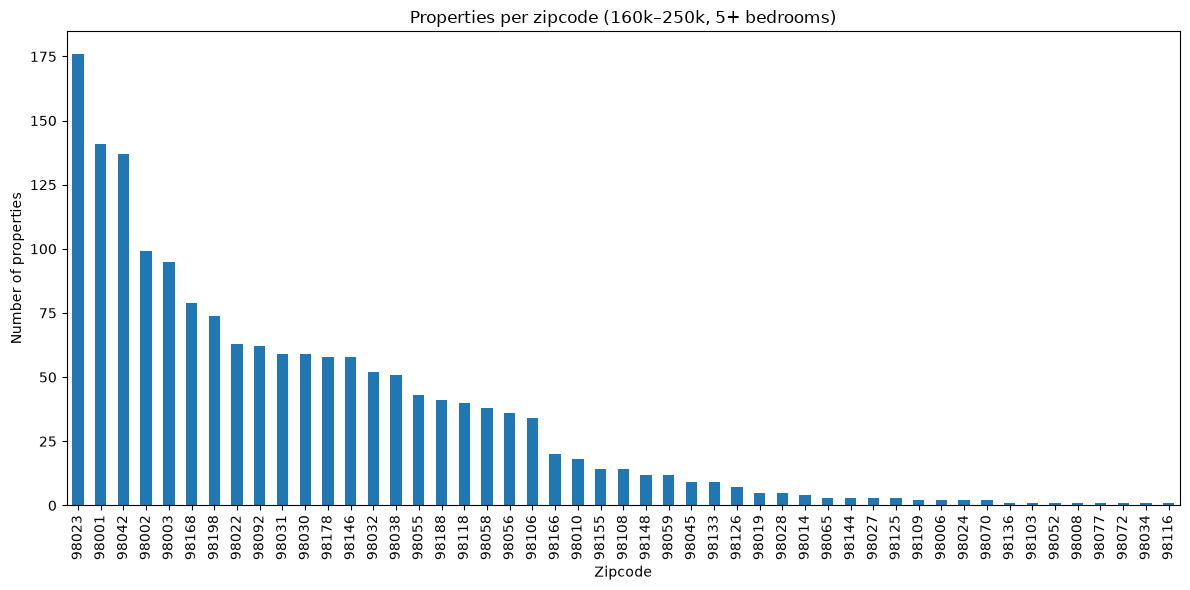

In [3]:

# 1. Filter: price between 100k and 250k, at least 5 bedrooms
df_filtered = df_house[
    (df_house["price"].between(160_000, 250_000)) &
    (df_house["bedrooms"] >= 3)
]
print(len(df_filtered), "properties")

# 2. Mean grade per zipcode
mean_grade = df_filtered.groupby("zipcode")["grade"].mean().round(2)
print(mean_grade)

# 3. Number of properties per zipcode
zip_counts = df_filtered["zipcode"].value_counts()

zip_counts.plot(kind="bar", figsize=(12, 6))
plt.title("Properties per zipcode (160k–250k, 5+ bedrooms)")
plt.xlabel("Zipcode")
plt.ylabel("Number of properties")
plt.xticks(rotation=90)
plt.tight_layout()
#plt.show()

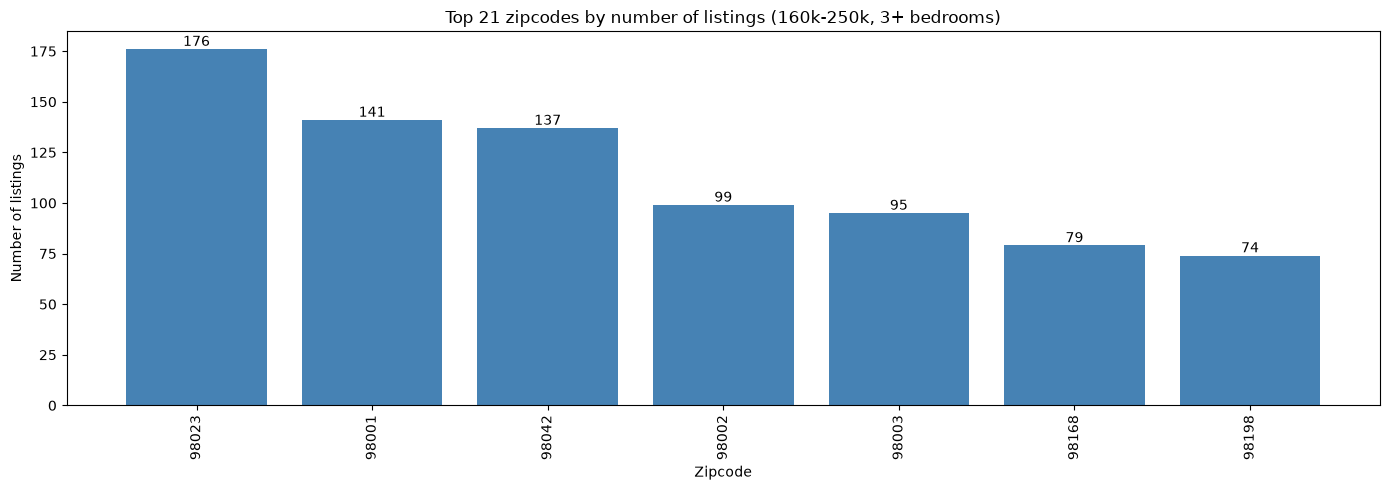

In [7]:
df = pd.read_csv("cleandataset.csv")

MIN_BEDROOMS = 3  # adjust the bedroom filter here

# Filter: price 160k-250k and at least MIN_BEDROOMS bedrooms
df_f = df[df["price"].between(160_000, 250_000) & (df["bedrooms"] >= MIN_BEDROOMS)]

# The 21 zipcodes with the most listings
top21_counts = df_f["zipcode"].value_counts().head(7)

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(top21_counts.index.astype(str), top21_counts.values, color="steelblue")
for bar, n in zip(bars, top21_counts.values):  # count above each bar
    ax.text(bar.get_x() + bar.get_width() / 2, n, str(n), ha="center", va="bottom")
ax.set_title(f"Top 21 zipcodes by number of listings (160k-250k, {MIN_BEDROOMS}+ bedrooms)")
ax.set_xlabel("Zipcode")
ax.set_ylabel("Number of listings")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


         n_listings  mean_condition  mean_grade  social_score
zipcode                                                      
98023           176            3.49        6.98          62.5
98001           141            3.49        6.87          59.9
98042           137            3.86        6.72          64.3
98002            99            3.94        6.57          67.5
98003            95            3.40        7.07          61.4
98168            79            3.16        6.49          59.2
98198            74            3.36        6.84          63.4


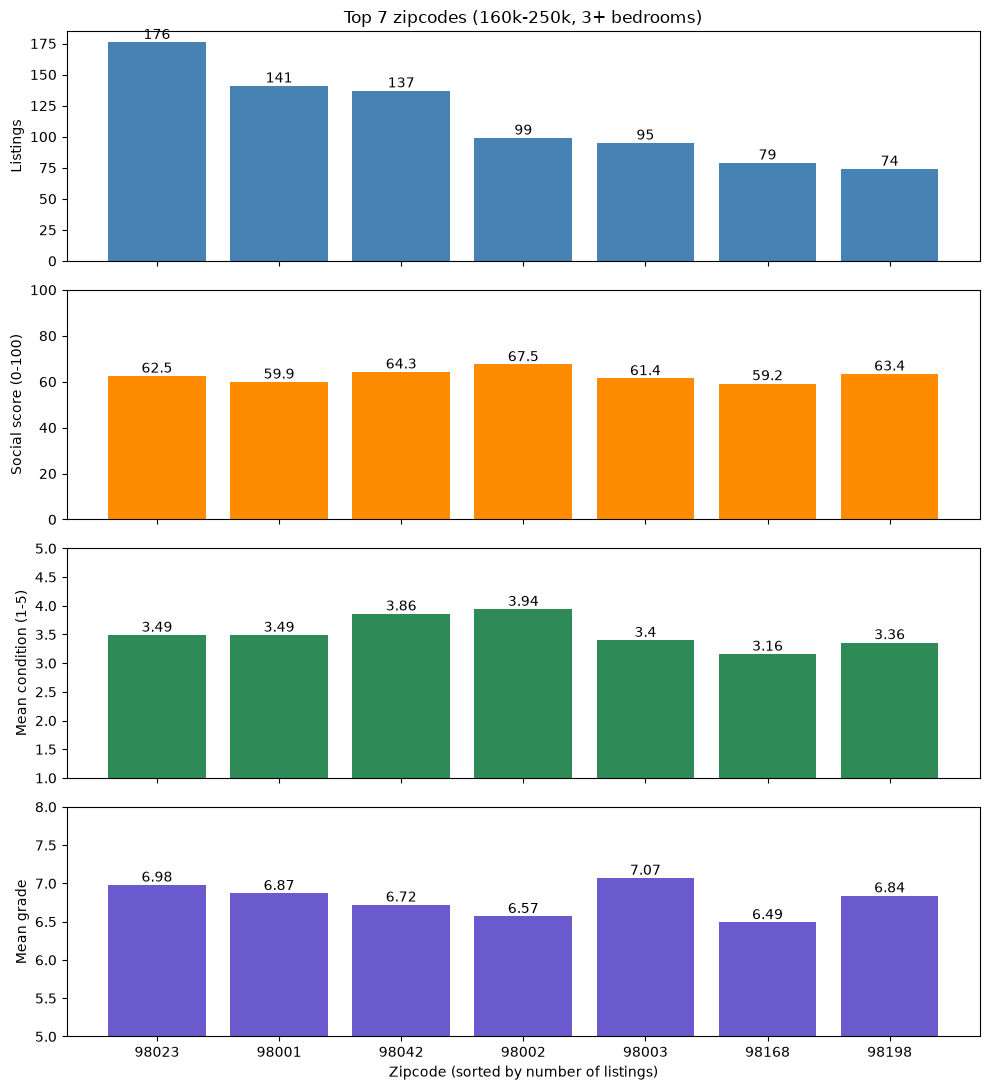

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cleandataset.csv")

MIN_BEDROOMS = 3   # bedroom filter
TOP_N = 7          # number of zipcodes to keep

# Social score per zipcode (same definition as 05_data_review), computed on ALL data:
# smaller neighbouring lots -> denser, more social neighborhood (0-100)
zip_lot = df.assign(log_lot15=np.log(df["sqft_lot15"])).groupby("zipcode")["log_lot15"].median()
social_score = (100 * (zip_lot.max() - zip_lot) / (zip_lot.max() - zip_lot.min())).round(1)

# Filter, then keep the TOP_N zipcodes with the most listings
df_f = df[df["price"].between(160_000, 250_000) & (df["bedrooms"] >= MIN_BEDROOMS)]
top_zips = df_f["zipcode"].value_counts().head(TOP_N).index

summary = (
    df_f[df_f["zipcode"].isin(top_zips)]
    .groupby("zipcode")
    .agg(
        n_listings=("price", "size"),
        mean_condition=("condition", "mean"),
        mean_grade=("grade", "mean"),
    )
    .round(2)
    .reindex(top_zips)  # keep order: most listings first
)
summary["social_score"] = social_score.reindex(summary.index)
print(summary)

# Plot: one panel per measure, same zipcode order
labels = summary.index.astype(str)
panels = [
    ("n_listings",     "Listings",              "steelblue",  None),
    ("social_score",   "Social score (0-100)",  "darkorange", (0, 100)),
    ("mean_condition", "Mean condition (1-5)",  "seagreen",   (1, 5)),
    ("mean_grade",     "Mean grade",            "slateblue",  (5, 8)),
]

fig, axes = plt.subplots(len(panels), 1, figsize=(10, 11), sharex=True)
for ax, (col, ylabel, color, ylim) in zip(axes, panels):
    bars = ax.bar(labels, summary[col], color=color)
    for bar, v in zip(bars, summary[col]):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:g}", ha="center", va="bottom")
    ax.set_ylabel(ylabel)
    if ylim:
        ax.set_ylim(*ylim)

axes[0].set_title(f"Top {TOP_N} zipcodes (160k-250k, {MIN_BEDROOMS}+ bedrooms)")
axes[-1].set_xlabel("Zipcode (sorted by number of listings)")
plt.tight_layout()
plt.show()



         n_listings  social_score  mean_condition  mean_grade  \
zipcode                                                         
98023           176          62.5            3.49        6.98   
98001           141          59.9            3.49        6.87   
98042           137          64.3            3.86        6.72   
98002            99          67.5            3.94        6.57   
98003            95          61.4            3.40        7.07   
98168            79          59.2            3.16        6.49   
98198            74          63.4            3.36        6.84   

         condition_all_zip  grade_all_zip  
zipcode                                    
98023                 3.39           7.58  
98001                 3.34           7.30  
98042                 3.52           7.42  
98002                 3.74           6.69  
98003                 3.37           7.54  
98168                 3.25           6.51  
98198                 3.44           7.10  


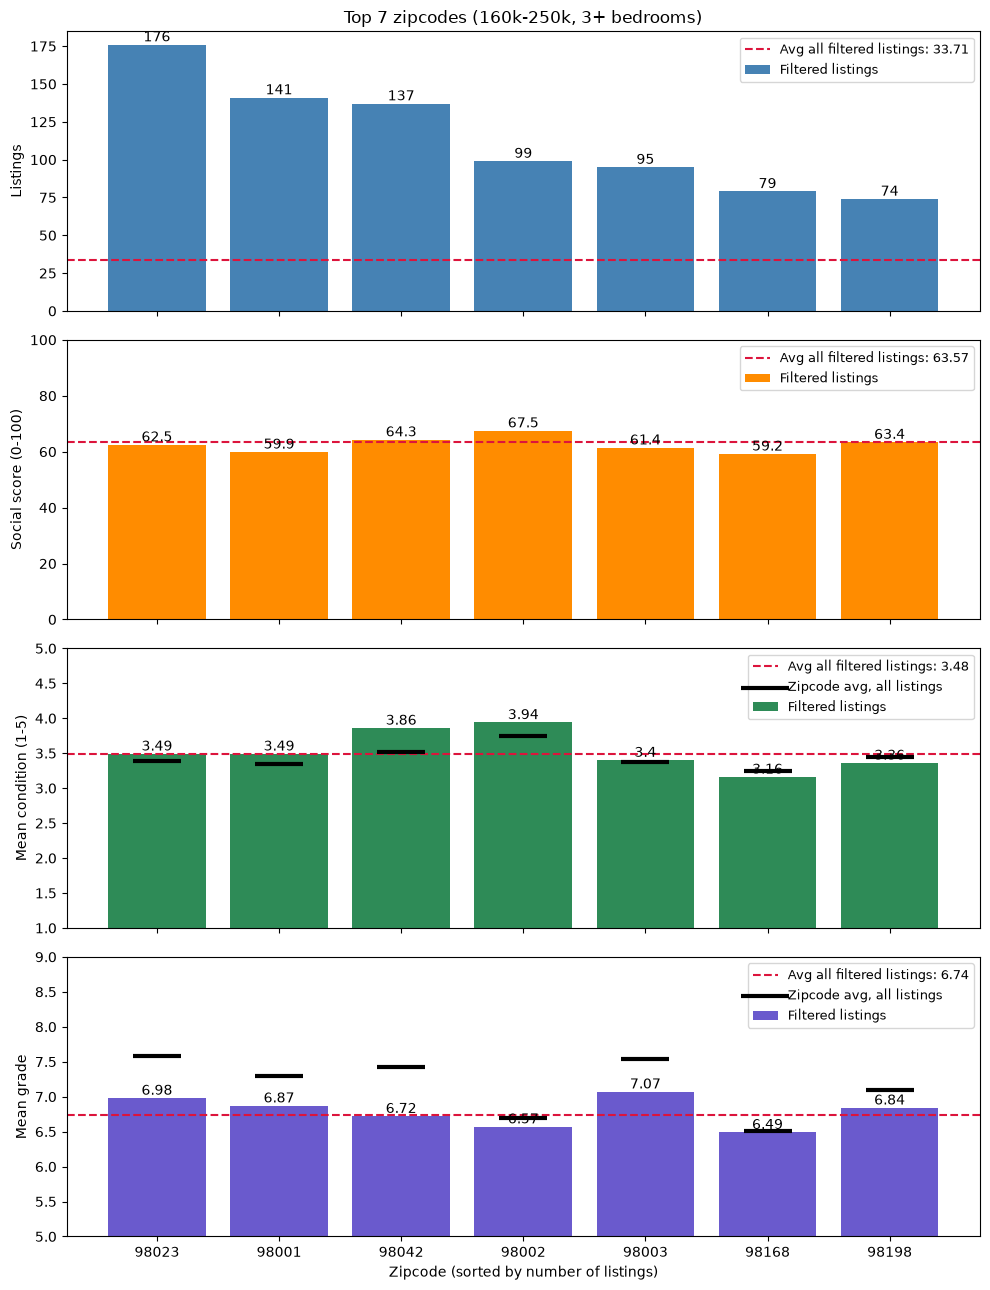

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cleandataset.csv")

MIN_BEDROOMS = 3   # bedroom filter
TOP_N = 7          # number of zipcodes to keep

# Social score per zipcode (same definition as 05_data_review), computed on ALL data
zip_lot = df.assign(log_lot15=np.log(df["sqft_lot15"])).groupby("zipcode")["log_lot15"].median()
social_score = (100 * (zip_lot.max() - zip_lot) / (zip_lot.max() - zip_lot.min())).round(1)

# Filter, attach each listing's zipcode social score
df_f = df[df["price"].between(160_000, 250_000) & (df["bedrooms"] >= MIN_BEDROOMS)].copy()
df_f["social_score"] = df_f["zipcode"].map(social_score)

# Keep the TOP_N zipcodes with the most listings
top_zips = df_f["zipcode"].value_counts().head(TOP_N).index

summary = (
    df_f[df_f["zipcode"].isin(top_zips)]
    .groupby("zipcode")
    .agg(
        n_listings=("price", "size"),
        social_score=("social_score", "first"),
        mean_condition=("condition", "mean"),
        mean_grade=("grade", "mean"),
    )
    .round(2)
    .reindex(top_zips)  # keep order: most listings first
)

# Per-zipcode averages over ALL listings (no price / bedroom filter)
zip_all = (
    df[df["zipcode"].isin(top_zips)]
    .groupby("zipcode")
    .agg(mean_condition=("condition", "mean"), mean_grade=("grade", "mean"))
    .round(2)
    .reindex(top_zips)
)
summary["condition_all_zip"] = zip_all["mean_condition"]
summary["grade_all_zip"] = zip_all["mean_grade"]
print(summary)

# Averages across ALL filtered listings (every zipcode)
overall = {
    "n_listings":     df_f["zipcode"].value_counts().mean(),  # avg listings per zipcode
    "social_score":   df_f["social_score"].mean(),
    "mean_condition": df_f["condition"].mean(),
    "mean_grade":     df_f["grade"].mean(),
}

# Plot: one panel per measure
labels = summary.index.astype(str)
panels = [
    ("n_listings",     "Listings",              "steelblue",  None),
    ("social_score",   "Social score (0-100)",  "darkorange", (0, 100)),
    ("mean_condition", "Mean condition (1-5)",  "seagreen",   (1, 5)),
    ("mean_grade",     "Mean grade",            "slateblue",  (5, 9)),
]
zip_all_cols = {"mean_condition": "condition_all_zip", "mean_grade": "grade_all_zip"}

fig, axes = plt.subplots(len(panels), 1, figsize=(10, 13), sharex=True)
for ax, (col, ylabel, color, ylim) in zip(axes, panels):
    bars = ax.bar(labels, summary[col], color=color, label="Filtered listings")
    for bar, v in zip(bars, summary[col]):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:g}", ha="center", va="bottom")

    # Dashed line: average across all filtered listings
    ax.axhline(overall[col], color="crimson", linestyle="--", linewidth=1.5,
               label=f"Avg all filtered listings: {overall[col]:.2f}")

    # Black tick per zipcode: average of ALL listings in that zipcode
    if col in zip_all_cols:
        ax.scatter(labels, summary[zip_all_cols[col]], marker="_", s=1200,
                   linewidths=3, color="black", zorder=3,
                   label="Zipcode avg, all listings")

    ax.legend(loc="upper right", fontsize=9)
    ax.set_ylabel(ylabel)
    if ylim:
        ax.set_ylim(*ylim)

axes[0].set_title(f"Top {TOP_N} zipcodes (160k-250k, {MIN_BEDROOMS}+ bedrooms)")
axes[-1].set_xlabel("Zipcode (sorted by number of listings)")
plt.tight_layout()
plt.show()

